In [1]:
from ultralytics import YOLO
import torch
from glob import glob
import cv2
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd
from pathlib import Path

print(torch.cuda.is_available(), torch.cuda.get_device_name(0) if torch.cuda.is_available() else "")

True NVIDIA GeForce RTX 4070 Laptop GPU


In [2]:
CLASS_NAMES = {
    0: "ignored", 1: "pedestrian", 2: "people", 3: "bicycle", 4: "car", 5: "van",
    6: "truck", 7: "tricycle", 8: "awning-tricycle", 9: "bus", 10: "motor", 11: "others",
}

CLASS_COLORS = {
    0: "gray", 1: "crimson", 2: "darkorange", 3: "gold", 4: "limegreen", 5: "turquoise",
    6: "dodgerblue", 7: "darkorchid", 8: "magenta", 9: "sienna", 10: "pink", 11: "white",
}

images = glob(r"data\VisDrone2019-DET-val\images\*")
labels = glob(r"data\VisDrone2019-DET-val\annotations\*")

In [3]:
thing = Path(images[1])
thing.stem

'0000001_03499_d_0000006'

In [4]:
image_id.stem

NameError: name 'image_id' is not defined

(np.float64(-0.5), np.float64(1919.5), np.float64(1079.5), np.float64(-0.5))

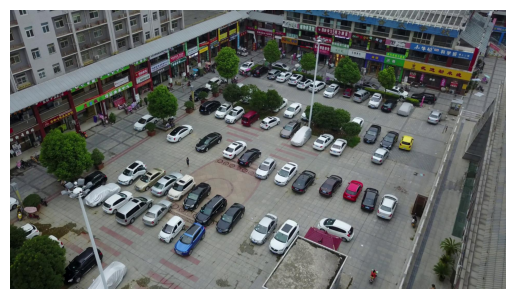

In [5]:
index = 5
image = cv2.imread(images[index])                 # loads as BGR uint8, shape (H, W, 3)
image_id = Path(images[index]).stem
image_annotations = pd.read_csv(r"data\\VisDrone2019-DET-val\\annotations\\"+"{}.txt".format(image_id), header=None).to_numpy()
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis("off")

In [6]:
def add_boxes(image, annotations):
    '''
    Extract bounding box pixel info and make a box
    '''
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    ax = plt.gca()

    for annotation in annotations:
        bbox_left, bbox_top, bbox_width, bbox_height, score, category, truncation, occlusion = annotation

        rect = matplotlib.patches.Rectangle((bbox_left, bbox_top), bbox_width, bbox_height, edgecolor=CLASS_COLORS[category], fc='none', lw = 1)
        ax.add_patch(rect)

    plt.axis("off")
    plt.show()

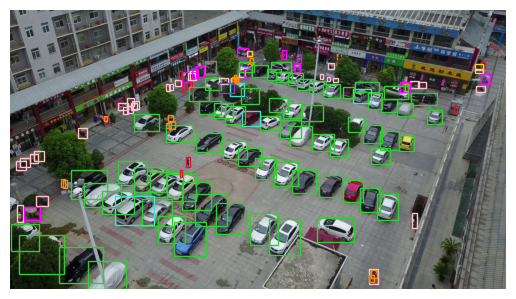

In [7]:
add_boxes(image, image_annotations)